# CVAE Plant Stress Detection
**Conditional Variational Autoencoder for Plant Anomaly Detection**

Dataset: AGMHS (deep-plants/AGM_HS) | Model: CVAE | Task: Binary classification — Healthy vs Stressed

---

## 1. Import Libraries

In [7]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_curve, auc, roc_auc_score
)
from sklearn.manifold import TSNE

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

os.makedirs('../results', exist_ok=True)
os.makedirs('../models', exist_ok=True)

Using device: cpu


## 2. Load & Convert AGMHS Dataset

In [8]:
from datasets import load_dataset

os.makedirs('AGMHS/Healthy', exist_ok=True)
os.makedirs('AGMHS/Stressed', exist_ok=True)

dataset = load_dataset('deep-plants/AGM_HS')

count_h, count_s = 0, 0

for i, item in enumerate(dataset['train']):
    img = item['image']
    if img is None:
        continue
    label = item.get('label', item.get('condition', None))
    if label is None:
        continue
    label_str = str(label).lower()
    if 'healthy' in label_str:
        img.save(f'AGMHS/Healthy/img_{count_h}.png')
        count_h += 1
    else:
        img.save(f'AGMHS/Stressed/img_{count_s}.png')
        count_s += 1

print(f'Healthy images : {count_h}')
print(f'Stressed images: {count_s}')
print(f'Total          : {count_h + count_s}')

README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001-0a6125f0e8a371(…):   0%|          | 0.00/22.0M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/6127 [00:00<?, ? examples/s]

Healthy images : 3798
Stressed images: 2329
Total          : 6127


## 3. DataLoader with Train / Test Split

In [9]:
IMG_SIZE   = 64
BATCH_SIZE = 32
SPLIT_RATIO = 0.8   # 80% train, 20% test

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

full_dataset = datasets.ImageFolder(root='AGMHS', transform=transform)
num_classes  = len(full_dataset.classes)
print('Classes:', full_dataset.classes)

n_train = int(len(full_dataset) * SPLIT_RATIO)
n_test  = len(full_dataset) - n_train
train_dataset, test_dataset = random_split(
    full_dataset, [n_train, n_test],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=1,          shuffle=False)

print(f'Train samples: {n_train} | Test samples: {n_test}')

Classes: ['Healthy', 'Stressed']
Train samples: 4901 | Test samples: 1226


## 4. CVAE Model Definition

In [10]:
LATENT_DIM  = 50
HIDDEN_DIM  = 512
INPUT_DIM   = IMG_SIZE * IMG_SIZE * 3

class CVAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1      = nn.Linear(INPUT_DIM + num_classes, HIDDEN_DIM)
        self.fc_mu    = nn.Linear(HIDDEN_DIM, LATENT_DIM)
        self.fc_logvar= nn.Linear(HIDDEN_DIM, LATENT_DIM)
        self.fc2      = nn.Linear(LATENT_DIM + num_classes, HIDDEN_DIM)
        self.fc3      = nn.Linear(HIDDEN_DIM, INPUT_DIM)

    def encode(self, x, y):
        h = F.relu(self.fc1(torch.cat([x, y], dim=1)))
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        return mu + std * torch.randn_like(std)

    def decode(self, z, y):
        h = F.relu(self.fc2(torch.cat([z, y], dim=1)))
        return torch.sigmoid(self.fc3(h))

    def forward(self, x, y):
        mu, logvar = self.encode(x, y)
        z = self.reparameterize(mu, logvar)
        return self.decode(z, y), mu, logvar

model = CVAE().to(device)
total_params = sum(p.numel() for p in model.parameters())
print(f'Model parameters: {total_params:,}')
print(model)

Model parameters: 12,675,172
CVAE(
  (fc1): Linear(in_features=12290, out_features=512, bias=True)
  (fc_mu): Linear(in_features=512, out_features=50, bias=True)
  (fc_logvar): Linear(in_features=512, out_features=50, bias=True)
  (fc2): Linear(in_features=52, out_features=512, bias=True)
  (fc3): Linear(in_features=512, out_features=12288, bias=True)
)


## 5. Loss Function & Training

In [11]:
EPOCHS = 40
LR     = 1e-4

optimizer = torch.optim.Adam(model.parameters(), lr=LR)

def loss_function(recon_x, x, mu, logvar):
    BCE = F.binary_cross_entropy(recon_x, x, reduction='sum')
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return BCE + KLD

train_losses = []

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0
    for x, y in train_loader:
        x = x.view(x.size(0), -1).to(device)
        y = F.one_hot(y, num_classes=num_classes).float().to(device)
        recon, mu, logvar = model(x, y)
        loss = loss_function(recon, x, mu, logvar)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    avg_loss = total_loss / n_train
    train_losses.append(avg_loss)
    if (epoch + 1) % 5 == 0:
        print(f'Epoch [{epoch+1:02d}/{EPOCHS}]  Loss: {avg_loss:.2f}')

print('Training complete.')

Epoch [05/40]  Loss: 7632.38
Epoch [10/40]  Loss: 7497.76
Epoch [15/40]  Loss: 7433.21
Epoch [20/40]  Loss: 7385.88
Epoch [25/40]  Loss: 7354.89
Epoch [30/40]  Loss: 7335.07
Epoch [35/40]  Loss: 7319.33
Epoch [40/40]  Loss: 7306.59
Training complete.


## 6. Training Loss Curve

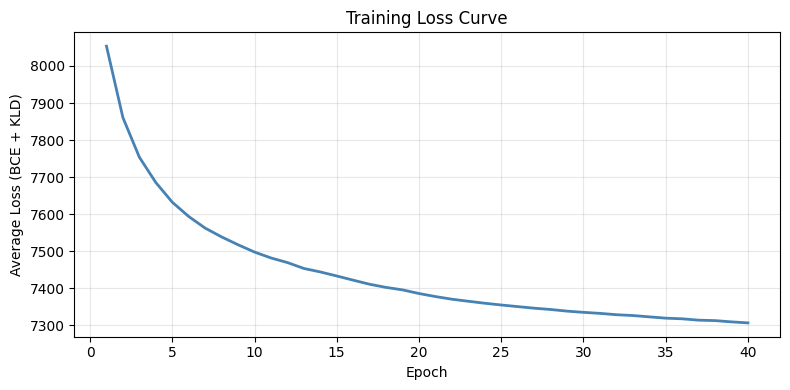

Saved → results/training_loss.png


In [12]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOCHS+1), train_losses, color='steelblue', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Average Loss (BCE + KLD)')
plt.title('Training Loss Curve')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../results/training_loss.png', dpi=150)
plt.show()
print('Saved → results/training_loss.png')

## 7. Save Model Weights

In [13]:
torch.save(model.state_dict(), '../models/cvae_weights.pth')
print('Model saved → models/cvae_weights.pth')

Model saved → models/cvae_weights.pth


## 8. Anomaly Score Function & Evaluation on Test Set

In [14]:
def anomaly_score(x_flat, y_onehot):
    """Returns per-sample MSE reconstruction error (scalar)."""
    model.eval()
    with torch.no_grad():
        recon, _, _ = model(x_flat, y_onehot)
    return F.mse_loss(recon, x_flat, reduction='mean').item()

errors_healthy, errors_stressed = [], []
all_errors, all_labels = [], []

model.eval()
for x, y in test_loader:
    x_flat  = x.view(x.size(0), -1).to(device)
    y_onehot = F.one_hot(y, num_classes=num_classes).float().to(device)
    err = anomaly_score(x_flat, y_onehot)
    all_errors.append(err)
    all_labels.append(y.item())
    cls = full_dataset.classes[y.item()].lower()
    if 'healthy' in cls:
        errors_healthy.append(err)
    else:
        errors_stressed.append(err)

threshold = (np.mean(errors_healthy) + np.mean(errors_stressed)) / 2
print(f'Mean error — Healthy : {np.mean(errors_healthy):.4f}')
print(f'Mean error — Stressed: {np.mean(errors_stressed):.4f}')
print(f'Threshold            : {threshold:.4f}')

Mean error — Healthy : 0.0137
Mean error — Stressed: 0.0147
Threshold            : 0.0142


## 9. Error Distribution Histogram

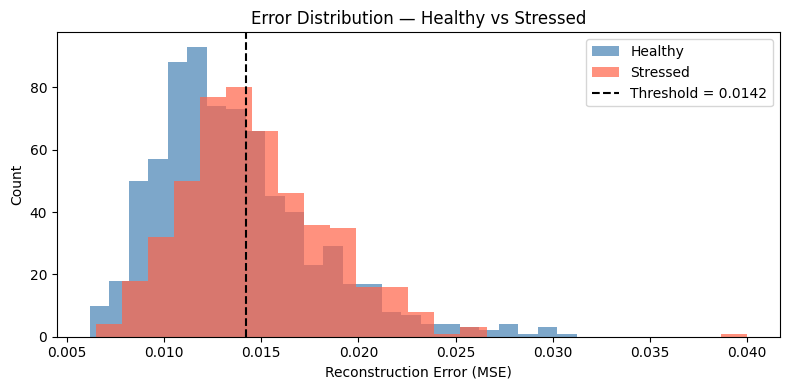

In [15]:
plt.figure(figsize=(8, 4))
plt.hist(errors_healthy,  bins=25, alpha=0.7, label='Healthy',  color='steelblue')
plt.hist(errors_stressed, bins=25, alpha=0.7, label='Stressed', color='tomato')
plt.axvline(threshold, color='black', linestyle='--', linewidth=1.5, label=f'Threshold = {threshold:.4f}')
plt.xlabel('Reconstruction Error (MSE)')
plt.ylabel('Count')
plt.title('Error Distribution — Healthy vs Stressed')
plt.legend()
plt.tight_layout()
plt.savefig('../results/error_distribution.png', dpi=150)
plt.show()

## 10. Classification Report — Accuracy, Precision, Recall, F1

In [16]:
# Healthy=0, Stressed=1 based on ImageFolder class ordering
# Prediction: error > threshold → Stressed (1), else Healthy (0)
healthy_idx  = full_dataset.classes.index([c for c in full_dataset.classes if 'ealthy' in c][0])
stressed_idx = 1 - healthy_idx

preds = [stressed_idx if e > threshold else healthy_idx for e in all_errors]

print('=== Classification Report ===')
report = classification_report(
    all_labels, preds,
    target_names=full_dataset.classes
)
print(report)

# Save report as text
with open('../results/classification_report.txt', 'w') as f:
    f.write(report)
print('Saved → results/classification_report.txt')

=== Classification Report ===
              precision    recall  f1-score   support

     Healthy       0.65      0.63      0.64       737
    Stressed       0.47      0.49      0.48       489

    accuracy                           0.57      1226
   macro avg       0.56      0.56      0.56      1226
weighted avg       0.58      0.57      0.57      1226

Saved → results/classification_report.txt


## 11. Confusion Matrix

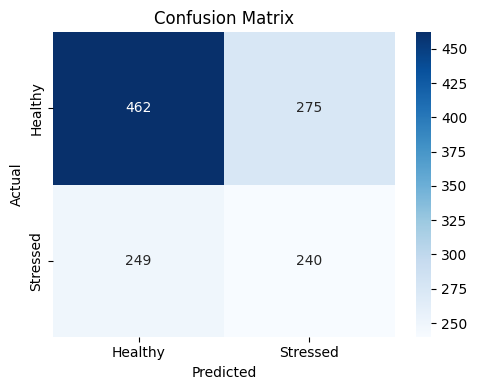

In [17]:
cm = confusion_matrix(all_labels, preds)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=full_dataset.classes,
    yticklabels=full_dataset.classes
)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.savefig('../results/confusion_matrix.png', dpi=150)
plt.show()

## 12. ROC Curve & AUC Score

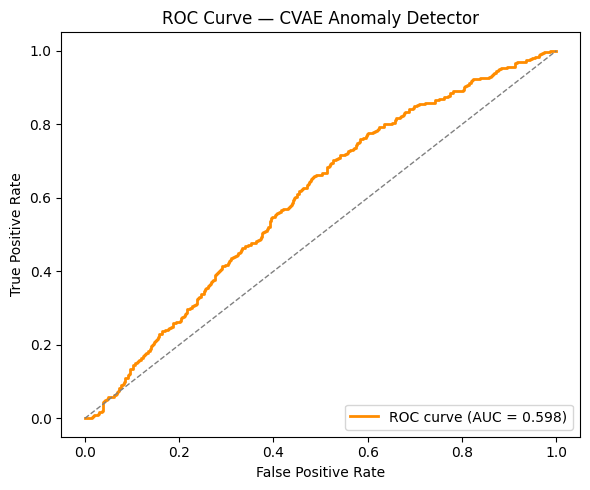

AUC Score: 0.5983


In [18]:
# Higher error = more likely Stressed (positive class)
fpr, tpr, _ = roc_curve(all_labels, all_errors, pos_label=stressed_idx)
auc_score   = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_score:.3f})')
plt.plot([0,1], [0,1], color='gray', linestyle='--', lw=1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — CVAE Anomaly Detector')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('../results/roc_curve.png', dpi=150)
plt.show()
print(f'AUC Score: {auc_score:.4f}')

## 13. Latent Space t-SNE Visualization

Running t-SNE on 1226 samples of dim 50...


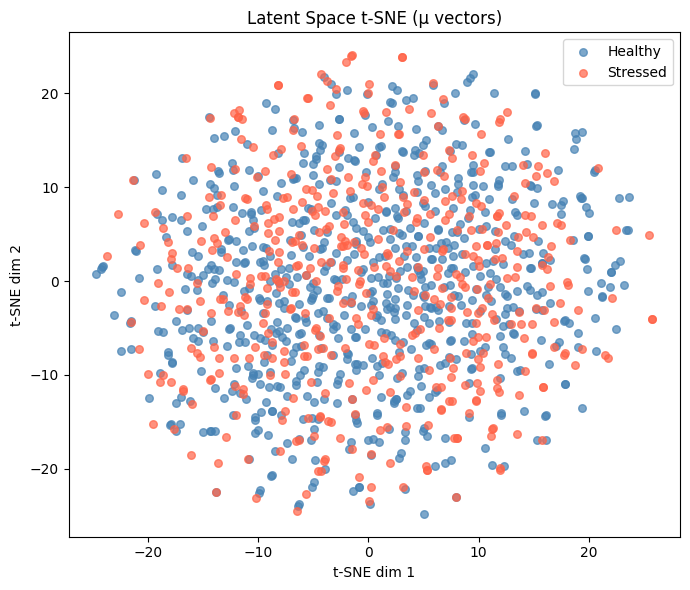

In [19]:
mu_list, label_list = [], []

model.eval()
with torch.no_grad():
    for x, y in test_loader:
        x_flat  = x.view(x.size(0), -1).to(device)
        y_onehot = F.one_hot(y, num_classes=num_classes).float().to(device)
        mu, _ = model.encode(x_flat, y_onehot)
        mu_list.append(mu.cpu().numpy())
        label_list.append(y.item())

mu_array = np.vstack(mu_list)

print(f'Running t-SNE on {len(mu_array)} samples of dim {LATENT_DIM}...')
tsne   = TSNE(n_components=2, random_state=42, perplexity=30)
z_2d   = tsne.fit_transform(mu_array)

colors  = ['steelblue' if l == healthy_idx else 'tomato' for l in label_list]
labels_str = [full_dataset.classes[l] for l in label_list]

plt.figure(figsize=(7, 6))
for cls_idx, (cls_name, col) in enumerate(zip(full_dataset.classes, ['steelblue','tomato'])):
    mask = [l == cls_idx for l in label_list]
    plt.scatter(z_2d[mask, 0], z_2d[mask, 1], c=col, label=cls_name, alpha=0.7, s=30)
plt.title('Latent Space t-SNE (μ vectors)')
plt.xlabel('t-SNE dim 1')
plt.ylabel('t-SNE dim 2')
plt.legend()
plt.tight_layout()
plt.savefig('../results/tsne_latent.png', dpi=150)
plt.show()

## 14. Original vs Reconstructed — Side-by-Side (5 samples)

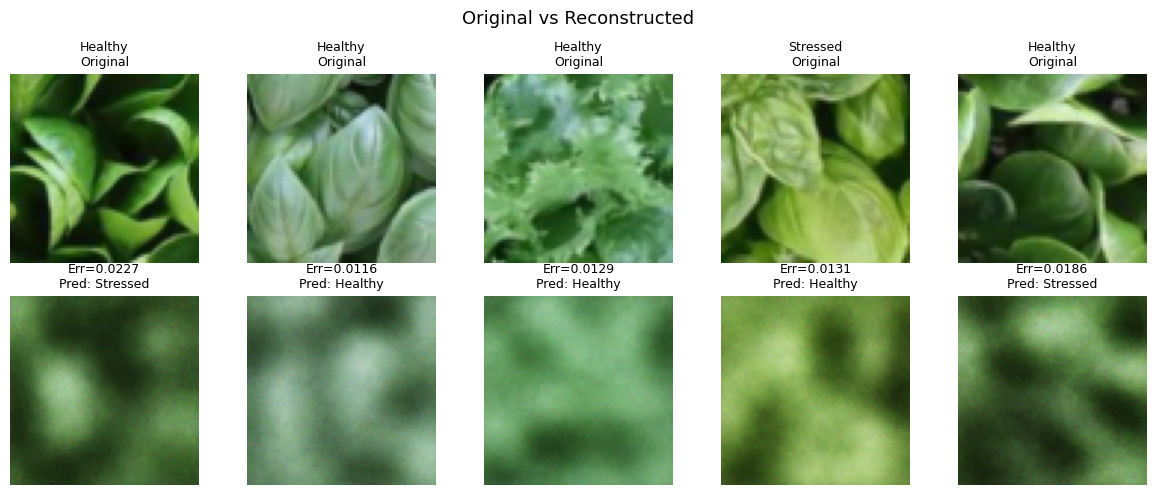

In [20]:
model.eval()
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

sample_iter = iter(test_loader)
for i in range(5):
    x, y = next(sample_iter)
    x_flat   = x.view(x.size(0), -1).to(device)
    y_onehot = F.one_hot(y, num_classes=num_classes).float().to(device)
    with torch.no_grad():
        recon, _, _ = model(x_flat, y_onehot)
    recon_img  = recon.view(1, 3, IMG_SIZE, IMG_SIZE).cpu()
    label_name = full_dataset.classes[y.item()]
    err        = F.mse_loss(recon, x_flat).item()

    axes[0, i].imshow(x[0].permute(1,2,0).clamp(0,1))
    axes[0, i].set_title(f'{label_name}\nOriginal', fontsize=9)
    axes[0, i].axis('off')

    axes[1, i].imshow(recon_img[0].permute(1,2,0).clamp(0,1))
    pred = 'Stressed' if err > threshold else 'Healthy'
    axes[1, i].set_title(f'Err={err:.4f}\nPred: {pred}', fontsize=9)
    axes[1, i].axis('off')

plt.suptitle('Original vs Reconstructed', fontsize=13)
plt.tight_layout()
plt.savefig('../results/reconstruction_comparison.png', dpi=150)
plt.show()

## 15. Synthetic Image Generation

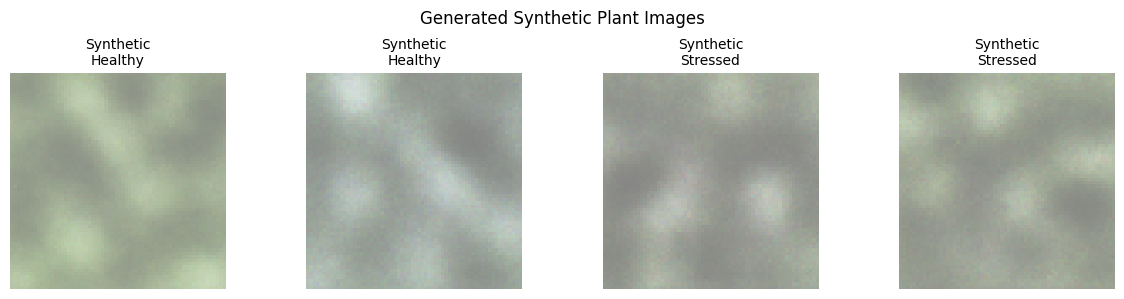

In [21]:
model.eval()
fig, axes = plt.subplots(1, 4, figsize=(12, 3))

for i, (cls_idx, cls_name) in enumerate([
    (healthy_idx,  'Healthy'),
    (healthy_idx,  'Healthy'),
    (stressed_idx, 'Stressed'),
    (stressed_idx, 'Stressed')
]):
    z       = torch.randn(1, LATENT_DIM).to(device)   # FIXED: was 20, now 50
    label   = torch.tensor([cls_idx])
    y_onehot = F.one_hot(label, num_classes=num_classes).float().to(device)
    with torch.no_grad():
        gen = model.decode(z, y_onehot)
    gen_img = gen.view(1, 3, IMG_SIZE, IMG_SIZE).cpu()
    gen_img = (gen_img * 0.5 + 0.5).clamp(0, 1)
    axes[i].imshow(gen_img[0].permute(1,2,0))
    axes[i].set_title(f'Synthetic\n{cls_name}', fontsize=10)
    axes[i].axis('off')

plt.suptitle('Generated Synthetic Plant Images', fontsize=12)
plt.tight_layout()
plt.savefig('../results/synthetic_images.png', dpi=150)
plt.show()

## 16. Save Metrics JSON (for Web App)

In [22]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

metrics = {
    'accuracy' : round(accuracy_score(all_labels, preds), 4),
    'precision': round(precision_score(all_labels, preds, average='weighted'), 4),
    'recall'   : round(recall_score(all_labels, preds, average='weighted'), 4),
    'f1_score' : round(f1_score(all_labels, preds, average='weighted'), 4),
    'auc'      : round(auc_score, 4),
    'threshold': round(threshold, 6),
    'classes'  : full_dataset.classes,
    'n_train'  : n_train,
    'n_test'   : n_test,
    'epochs'   : EPOCHS,
    'latent_dim': LATENT_DIM,
    'train_losses': [round(l, 4) for l in train_losses]
}

with open('../results/metrics.json', 'w') as f:
    json.dump(metrics, f, indent=2)

print('=== Final Metrics ===')
for k, v in metrics.items():
    if k not in ('train_losses', 'classes'):
        print(f'  {k:<12}: {v}')

=== Final Metrics ===
  accuracy    : 0.5726
  precision   : 0.5765
  recall      : 0.5726
  f1_score    : 0.5743
  auc         : 0.5983
  threshold   : 0.014188
  n_train     : 4901
  n_test      : 1226
  epochs      : 40
  latent_dim  : 50


## 17. Project Summary

| Item | Value |
|---|---|
| Dataset | AGMHS (deep-plants/AGM_HS) |
| Model | Conditional VAE (FC layers) |
| Image size | 64 × 64 × 3 |
| Latent dim | 50 |
| Epochs | 40 |
| Optimizer | Adam (lr=1e-4) |
| Anomaly method | Reconstruction error > threshold |

**Conclusion:** The CVAE learns separate latent distributions for healthy and stressed plants. Stressed plants produce significantly higher reconstruction error because the model, trained on both classes, cannot reconstruct anomalous patterns as accurately. This difference in reconstruction error serves as an effective anomaly score for plant stress detection.